# The dose-rescaling census — eval-time λ·ΔW on every run of every arm

**Question.** The boundary law says a run collapses when its realized update size (Frobenius
dose, `dw_fro`) crosses an arm-level tolerance θ. The λ-crossing test (ICLR §4.3) checked this on
24 near-boundary runs per arm by dialing each trained update `W = W0 + λ·ΔW` until the receiver
crossed the unigram-anchored bar, and found per-run crossing sizes ≈ θ. This notebook is the
**census version**: every run of every in-scope arm is evaluated at 13 arm-normalized dose ratios
`g = λ·dw_fro / θ_arm ∈ {0.15 … 2.6}` (λ = g·θ/dw_fro is frozen per run in the manifest, no
training-time clamp), with pp1 ΔCE, Pile-KL and the trait probability read at every rung.

**Artifacts.** `analysis/dose_rescaling_census_20260902/` — every `manifest*.json` /
`results*.csv` pair in the directory is one slice of a single census population (the notebook
loads them all and asserts each results row carries its manifest's sha). θ per arm was fitted once
by `fit_anchored_dose_threshold` on the endpoint outcomes of the 2,884 runs planned 2026-09-02 and
held fixed for the cells that completed each arm's boundary window afterwards (147 cells landed
2026-09-02; the 2026-09-03 completion cells are absorbed automatically when their results land) —
Angela: "fine to use the same fitted threshold for now". Design + evaluator:
`src/subliminal_learning/weightspace/dose_rescaling.py`, `dose_census.py`; CLI
`scripts/dose_rescaling_census.py`.

**Conventions.** Dead = the OPERATIVE anchored cut of the receiver base (ΔCE > H_uni − CE_base;
`probe_io.anchored_dead_cut`); the census records the cut per run. Row units are stated on every
table. "Per-run crossing ratio" g× = the dose ratio at which the run's ΔCE(g) crosses its cut,
log-linearly interpolated between adjacent rungs (undefined if the run is dead at g = 0.15 or alive
at g = 2.6). "Endpoint ratio" e = dw_fro / θ_arm is where the run's *own* training ended on the same
axis; λ = 1 sits at g = e. Figures go to `analysis/dose_rescaling_census_20260902/figures/`.

In [1]:
import json, warnings, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

from subliminal_learning.config import resolve_roots
from subliminal_learning.analysis.setup import set_plot_style

set_plot_style()
OUT, _ = resolve_roots(None, None)
C = OUT / 'analysis' / 'dose_rescaling_census_20260902'
FIG = C / 'figures'; FIG.mkdir(exist_ok=True)
RATIOS = None

def load_slice(man, res):
    '''One (manifest, results) pair of the census; all pairs in the directory form one population.'''
    m = json.loads(man.read_text()); r = pd.read_csv(res)
    assert (r.manifest_sha256 == m['manifest_sha256']).all(), f'{res.name}: results/manifest sha mismatch'
    td = {x['run_path']: x for x in m['runs']}
    r['trained_dead'] = r.run_path.map(lambda p: bool(td[p]['trained_dead']))
    r['trained_delta_ce'] = r.run_path.map(lambda p: td[p]['trained_delta_ce'])
    r['student_tag'] = r.run_path.map(lambda p: td[p]['student_tag'])
    return m, r

slices = {}
for man in sorted(C.glob('manifest*.json')):
    res = C / man.name.replace('manifest', 'results').replace('.json', '.csv')
    if res.exists():
        slices[man.stem[len('manifest'):].lstrip('_') or 'plan'] = load_slice(man, res)
MAN = slices['plan'][0]
RATIOS = [float(x) for x in MAN['design']['dose_ratios']]
for m in slices.values():
    assert [float(x) for x in m[0]['design']['dose_ratios']] == RATIOS, 'all slices must share the dose-ratio ladder'
D = pd.concat([s[1] for s in slices.values()], ignore_index=True)
assert D.groupby('run_path').manifest_sha256.nunique().max() == 1, 'a run may appear in only one manifest'
D['e'] = D.endpoint_dw_fro / D.theta            # endpoint dose ratio (λ = 1 sits here)
D['g'] = D.dose_ratio
ARMS = ['strip', 'orig_same_model', 'trait_free', 'sgd', 'm410_same_model', 'm410_cross_seed', 'teachers']
LABEL = {'strip': 'cross data order (strip)', 'orig_same_model': 'orig same-model', 'trait_free': 'trait-free',
         'sgd': 'SGD', 'm410_same_model': '410M same-model', 'm410_cross_seed': '410M cross-seed', 'teachers': 'teachers (dog|orig)'}
COL = dict(zip(ARMS, plt.rcParams['axes.prop_cycle'].by_key()['color']))
print('census slices loaded (points, runs):', {t: (len(s[1]), s[1].run_path.nunique()) for t, s in slices.items()})
print('dose ratios:', RATIOS)
print(f'points {len(D):,}, runs {D.run_path.nunique():,}, nonfinite readouts {int(D.nonfinite.sum())}')

census slices loaded (points, runs): {'plan': (37492, 2884), 'winfill': (1911, 147)}
dose ratios: [0.15, 0.25, 0.35, 0.5, 0.65, 0.8, 0.95, 1.1, 1.3, 1.55, 1.85, 2.2, 2.6]
points 39,403, runs 3,031, nonfinite readouts 0


## §1 Inventory — arms and thresholds

Row unit: one arm. θ is the arm's dose threshold (fitted once on the 2026-09-02 endpoint
outcomes, held fixed for the boundary-window cells that completed the arm afterwards), cut the
receiver's anchored ΔCE bar, "trained dead" the endpoint fate at λ = 1 that the census re-derives,
"e" the endpoint dose ratio dw_fro/θ. Runs are complete at all 13 rungs by construction (the
aggregate refuses partial shards).

In [2]:
inv = (D.groupby('arm')
         .agg(runs=('run_path', 'nunique'), theta=('theta', 'first'), cut=('anchored_delta_ce_cut', 'first'),
              trained_dead=('trained_dead', lambda s: int(s.groupby(D.loc[s.index, 'run_path']).first().sum())),
              e_median=('e', 'median'), e_min=('e', 'min'), e_max=('e', 'max'))
         .reset_index())
inv['arm'] = pd.Categorical(inv.arm, ARMS); inv = inv.sort_values('arm')
print('Table 1 — census inventory (row = arm; θ = arm dose threshold; e = endpoint dose ratio):')
print(inv.round(4).to_string(index=False))
inv.to_csv(FIG / 'table1_inventory.csv', index=False)

Table 1 — census inventory (row = arm; θ = arm dose threshold; e = endpoint dose ratio):
            arm  runs  theta    cut  trained_dead  e_median  e_min    e_max
          strip   934 0.1488 5.1234           390    0.6197 0.0112  87.4663
orig_same_model   368 0.1497 5.0963           204    1.1519 0.0101  75.3642
     trait_free   430 0.2617 5.1234           134    0.6225 0.0104  50.4695
            sgd   383 0.0383 5.0963           157    0.7251 0.0135 225.3023
m410_same_model   340 0.1864 5.4738            74    0.2561 0.0114   4.2812
m410_cross_seed   288 0.1893 5.4660            27    0.1713 0.0121   2.6926
       teachers   288 0.0094 5.0963           126    0.8306 0.0268   7.6335


## §2 Population rescaling curves — P(dead | g) and ΔCE(g)

The population readout: at each dose ratio, the fraction of an arm's runs whose rescaled update
crosses the bar, and the median ΔCE. If θ were a per-run invariant every curve would step from
0 to 1 at g = 1.

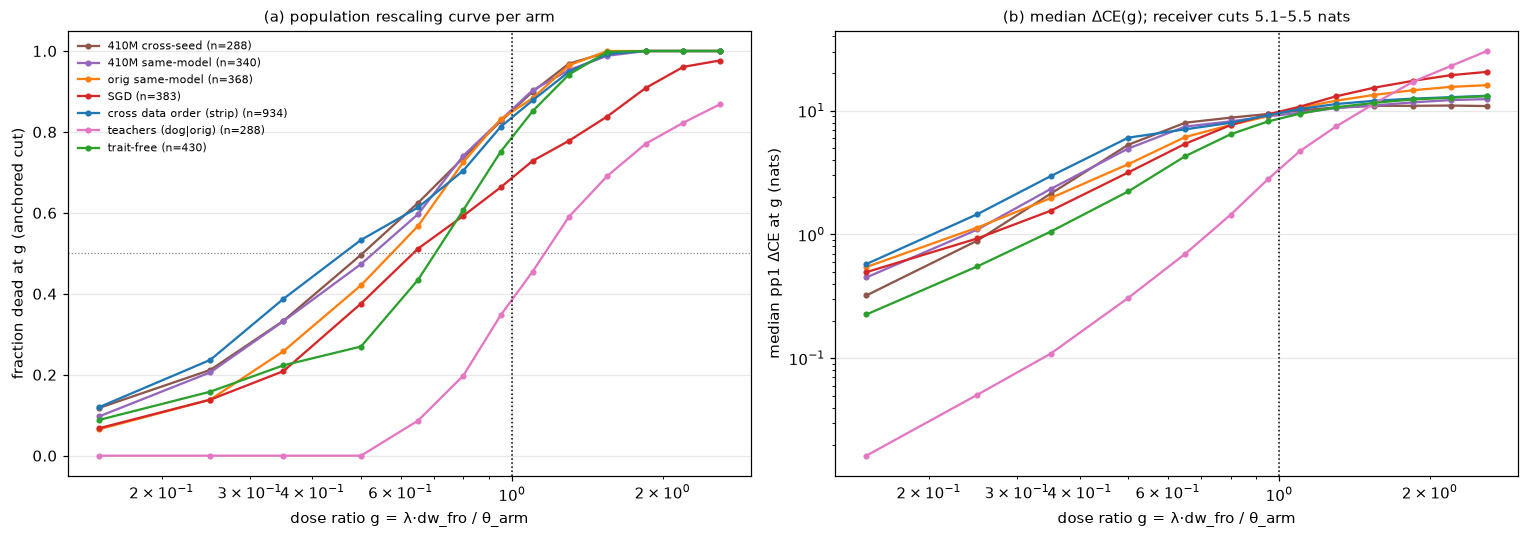

Table 2 — population rescaling summary (row = arm; g50 = dose ratio at which half the arm is dead):
            arm  runs  g50_population  dead_at_0p5  dead_at_0p95  dead_at_1p1  dead_at_1p55
          strip   934           0.461        0.533         0.813        0.878         0.993
orig_same_model   368           0.576        0.421         0.832        0.883         1.000
     trait_free   430           0.703        0.270         0.751        0.851         0.998
            sgd   383           0.635        0.376         0.663        0.728         0.838
m410_same_model   340           0.529        0.474         0.829        0.903         0.988
m410_cross_seed   288           0.504        0.497         0.826        0.899         0.997
       teachers   288           1.163        0.000         0.347        0.455         0.691


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for arm, g_ in D.groupby('arm'):
    curve = g_.groupby('g').agg(dead=('dead', 'mean'), dce=('delta_ce', 'median'), n=('run_path', 'nunique'))
    lab = f"{LABEL[arm]} (n={int(curve.n.iloc[0])})"
    axes[0].plot(curve.index, curve.dead, '-', marker='o', ms=3, color=COL[arm], label=lab)
    axes[1].plot(curve.index, curve.dce, '-', marker='o', ms=3, color=COL[arm])
for ax in axes:
    ax.axvline(1.0, color='k', lw=1, ls=':'); ax.set_xscale('log'); ax.set_xlabel('dose ratio g = λ·dw_fro / θ_arm')
axes[0].axhline(0.5, color='0.5', lw=0.8, ls=':'); axes[0].set_ylabel('fraction dead at g (anchored cut)')
axes[0].set_title('(a) population rescaling curve per arm', fontsize=10)
axes[1].set_ylabel('median pp1 ΔCE at g (nats)'); axes[1].set_yscale('log')
axes[1].set_title('(b) median ΔCE(g); receiver cuts 5.1–5.5 nats', fontsize=10)
axes[0].legend(fontsize=7, frameon=False, loc='upper left')
fig.tight_layout(); fig.savefig(FIG / 'fig1_population_curves.png', dpi=160, bbox_inches='tight'); plt.show()

def g50(curve):
    '''Population 50% crossing: log-linear interpolation of dead-fraction across g.'''
    x = np.log(curve.index.values); y = curve.values - 0.5
    if (y > 0).any() and (y < 0).any():
        i = int(np.argmax(y > 0)); return float(np.exp(x[i-1] + (x[i]-x[i-1]) * (-y[i-1]) / (y[i]-y[i-1]))) if i > 0 else np.nan
    return np.nan
t2 = []
for arm, g_ in D.groupby('arm'):
    curve = g_.groupby('g').dead.mean()
    t2.append(dict(arm=arm, runs=g_.run_path.nunique(), g50_population=g50(curve),
                   dead_at_0p5=curve.get(0.5), dead_at_0p95=curve.get(0.95), dead_at_1p1=curve.get(1.1), dead_at_1p55=curve.get(1.55)))
t2 = pd.DataFrame(t2); t2['arm'] = pd.Categorical(t2.arm, ARMS); t2 = t2.sort_values('arm')
print('Table 2 — population rescaling summary (row = arm; g50 = dose ratio at which half the arm is dead):')
print(t2.round(3).to_string(index=False)); t2.to_csv(FIG / 'table2_population_curves.csv', index=False)

## §3 Per-run crossing ratio g× — and why the census median is not 1

Every run has a monotone ΔCE(g) (checked below), so each has one crossing ratio g×. The λ-crossing
test's "crossing ≈ θ" was read on runs whose *own* endpoint sat near the boundary. The census asks
how g× depends on where the run's training ended (e = dw_fro/θ): if the tolerance were a fixed
size, g× would be 1 everywhere; if the outcome were a fixed *multiple of the trained size*
(λ* = g×/e constant), log g× would rise with slope 1 in log e.

In [4]:
def per_run(g_):
    g_ = g_.sort_values('g'); gs = g_.g.values; dead = g_.dead.values.astype(bool)
    y = g_.delta_ce.values - g_.anchored_delta_ce_cut.iloc[0]; x = np.log(gs)
    gc = np.nan
    if np.isfinite(y).all() and (y > 0).any() and (y < 0).any():
        i = int(np.argmax(y > 0))
        if i > 0: gc = float(np.exp(x[i-1] + (x[i]-x[i-1]) * (-y[i-1]) / (y[i]-y[i-1])))
    # trait: last rung at which the run still carries the trait (p_target > 0.02, the paper-figures criterion)
    carry = g_.p_target.values > 0.02
    return pd.Series(dict(g_cross=gc, dead_at_min=bool(dead[0]), alive_at_max=bool(~dead[-1]),
                          nonmono=int(((~dead[1:]) & dead[:-1]).sum()),
                          dce_nonmono=int((np.diff(np.log(np.clip(g_.delta_ce.values, 1e-6, None))) < -0.05).sum()),
                          trait_max_g=(gs[carry].max() if carry.any() else np.nan),
                          p_at_0p5=float(g_[g_.g.eq(0.5)].p_target.mean()), p_at_1p1=float(g_[g_.g.eq(1.1)].p_target.mean())))
R = D.groupby(['arm', 'run_path', 'rank', 'student_tag', 'e', 'trained_dead', 'trained_delta_ce']).apply(per_run).reset_index()
R['lambda_star'] = R.g_cross / R.e
print(f"runs {len(R):,}: crossing defined for {int(np.isfinite(R.g_cross).sum()):,}; dead already at g=0.15: {int(R.dead_at_min.sum())}; "
      f"alive at g=2.6: {int(R.alive_at_max.sum())}; runs with a dead→alive reversal along the ladder: {int((R.nonmono > 0).sum())}; "
      f"runs with any >5% ΔCE decrease between rungs: {int((R.dce_nonmono > 0).sum())}")
R.to_csv(FIG / 'per_run_crossings.csv', index=False)

runs 3,031: crossing defined for 2,717; dead already at g=0.15: 267; alive at g=2.6: 47; runs with a dead→alive reversal along the ladder: 0; runs with any >5% ΔCE decrease between rungs: 899


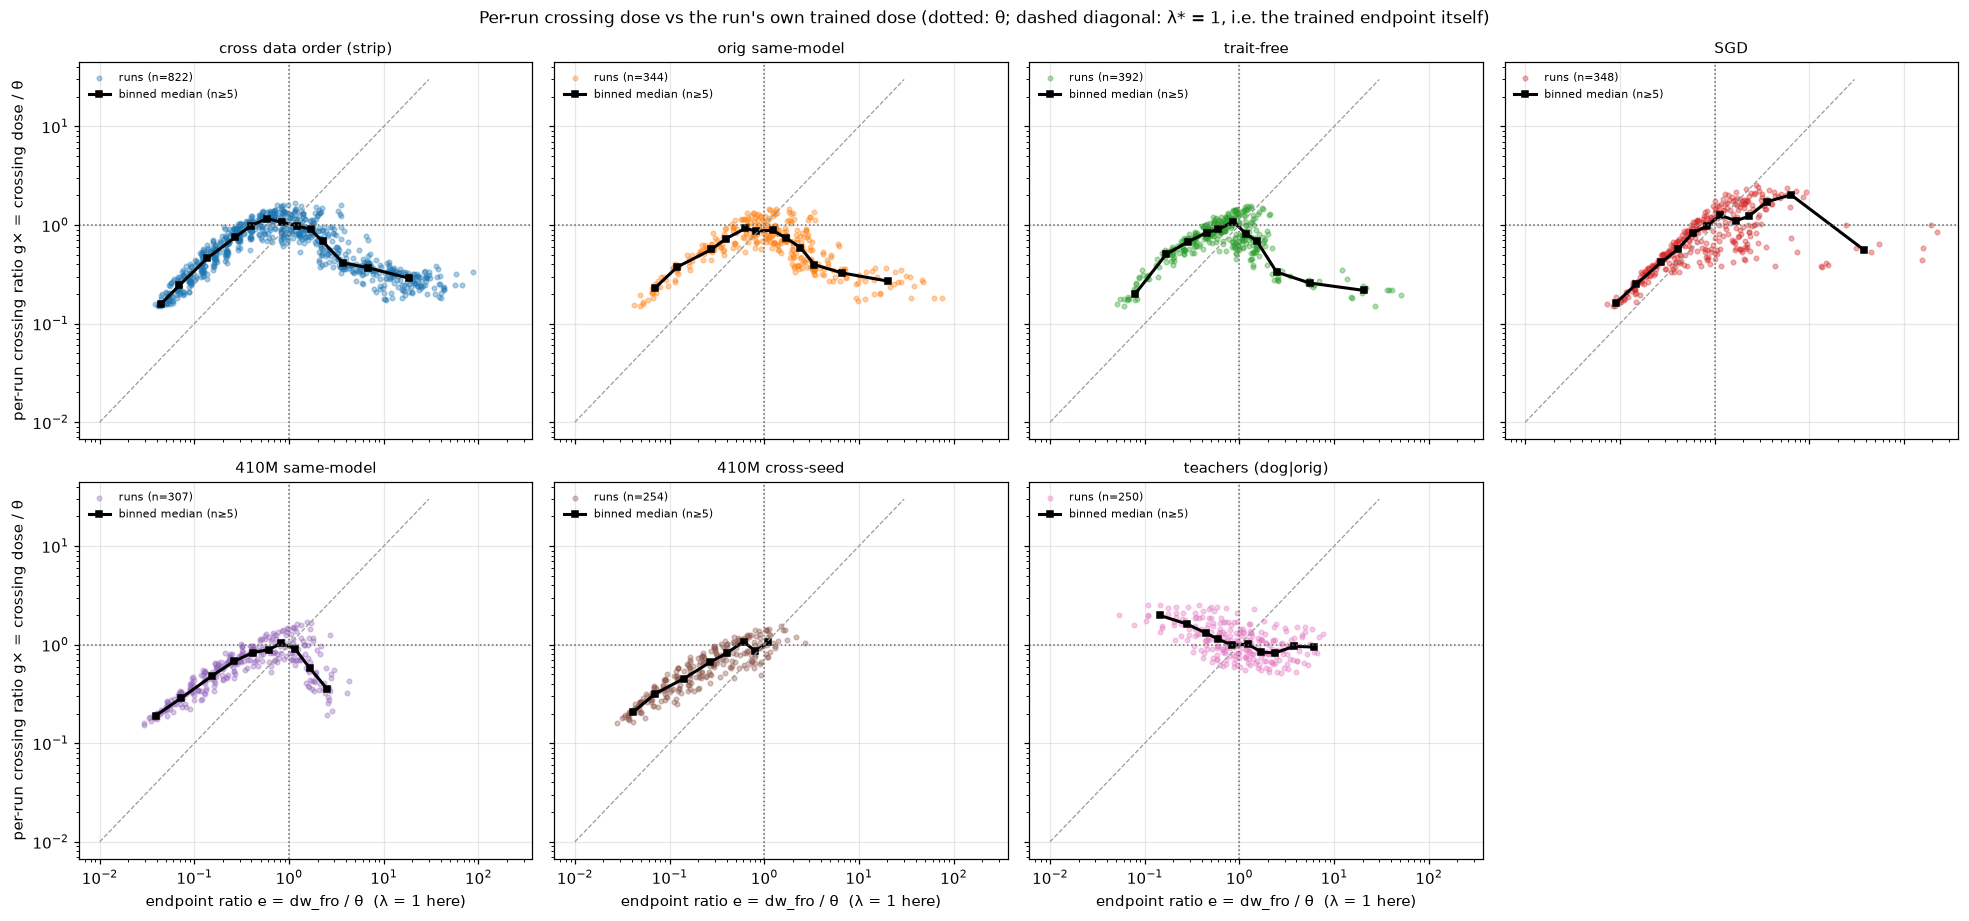

In [5]:
bins = [0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 3.0, 5.0, 10.0, np.inf]
Rf = R[np.isfinite(R.g_cross) & (R.e > 0)].copy(); Rf['ebin'] = pd.cut(Rf.e, bins)
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True, sharey=True); axes = axes.ravel()
for k, arm in enumerate(ARMS):
    ax = axes[k]; g_ = Rf[Rf.arm.eq(arm)]
    ax.scatter(g_.e, g_.g_cross, s=9, alpha=0.35, color=COL[arm], label=f'runs (n={len(g_)})')
    med = g_.groupby('ebin', observed=True).agg(e=('e', 'median'), gc=('g_cross', 'median'), n=('g_cross', 'size'))
    med = med[med.n >= 5]; ax.plot(med.e, med.gc, 'k-', lw=2, marker='s', ms=4, label='binned median (n≥5)')
    ax.axhline(1, color='0.4', ls=':', lw=1); ax.axvline(1, color='0.4', ls=':', lw=1)
    lo = np.array([1e-2, 30]); ax.plot(lo, lo, color='0.6', ls='--', lw=0.8)  # λ* = 1 diagonal
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(LABEL[arm], fontsize=10); ax.legend(fontsize=7, frameon=False)
    if k % 4 == 0: ax.set_ylabel('per-run crossing ratio g× = crossing dose / θ')
    if k >= 4: ax.set_xlabel('endpoint ratio e = dw_fro / θ  (λ = 1 here)')
axes[-1].axis('off')
fig.suptitle('Per-run crossing dose vs the run\'s own trained dose (dotted: θ; dashed diagonal: λ* = 1, i.e. the trained endpoint itself)', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'fig2_crossing_vs_endpoint.png', dpi=160, bbox_inches='tight'); plt.show()

In [6]:
rows = []
for arm, g_ in Rf.groupby('arm'):
    sub = g_
    below = sub[sub.e < 0.7]; nb = sub[(sub.e >= 0.7) & (sub.e <= 1.4)]; above = sub[sub.e > 1.4]
    def slope(x):
        if len(x) < 10: return (np.nan, np.nan, np.nan)
        m = sm.OLS(np.log(x.g_cross), sm.add_constant(np.log(x.e))).fit(); ci = m.conf_int().iloc[1]
        return (m.params.iloc[1], ci[0], ci[1])
    sb, sblo, sbhi = slope(below); sa, salo, sahi = slope(above)
    rows.append(dict(arm=arm, runs=len(sub), median_gx_all=sub.g_cross.median(),
                     median_gx_below=below.g_cross.median(), n_below=len(below),
                     median_gx_near=nb.g_cross.median(), n_near=len(nb),
                     median_gx_above=above.g_cross.median(), n_above=len(above),
                     slope_below=sb, slope_below_ci=f'[{sblo:.2f}, {sbhi:.2f}]',
                     slope_above=sa, slope_above_ci=f'[{salo:.2f}, {sahi:.2f}]',
                     median_lambda_star=sub.lambda_star.median()))
t3 = pd.DataFrame(rows); t3['arm'] = pd.Categorical(t3.arm, ARMS); t3 = t3.sort_values('arm')
print('Table 3 — per-run crossing ratio by where training ended (row = arm; below/near/above = e < 0.7 / 0.7–1.4 / > 1.4;')
print('          slope = OLS of log g× on log e within the segment, 95% CI; λ* = g×/e = the multiplier of the trained update at crossing):')
print(t3.round(3).to_string(index=False)); t3.to_csv(FIG / 'table3_crossing_by_endpoint.csv', index=False)

Table 3 — per-run crossing ratio by where training ended (row = arm; below/near/above = e < 0.7 / 0.7–1.4 / > 1.4;
          slope = OLS of log g× on log e within the segment, 95% CI; λ* = g×/e = the multiplier of the trained update at crossing):
            arm  runs  median_gx_all  median_gx_below  n_below  median_gx_near  n_near  median_gx_above  n_above  slope_below slope_below_ci  slope_above slope_above_ci  median_lambda_star
          strip   822          0.532            0.566      389           1.004     106            0.376      327        0.750   [0.72, 0.77]       -0.418 [-0.45, -0.38]               1.315
orig_same_model   344          0.609            0.556      111           0.877      76            0.448      157        0.649   [0.61, 0.69]       -0.395 [-0.45, -0.33]               0.665
     trait_free   392          0.740            0.728      202           0.992     123            0.519       67        0.671   [0.64, 0.71]       -0.440 [-0.53, -0.35]               1.4

## §4 Fate reconstruction and hysteresis

Two consistency readouts. (i) Because ΔCE(g) is monotone and λ = 1 sits at g = e, the trained fate
should be recovered as `e > g×`; mismatches count runs whose interpolated crossing lands on the
wrong side of their own endpoint (interpolation error between rungs). (ii) *Hysteresis*: trained-alive
runs that die when merely scaled up to a dose still below θ, and trained-dead runs that stay dead
when scaled down below θ — both are where the population threshold misreads the run.

In [7]:
Rv = R[np.isfinite(R.g_cross)].copy(); Rv['recon_dead'] = Rv.e > Rv.g_cross
t4 = (Rv.groupby('arm')
        .apply(lambda x: pd.Series(dict(runs=len(x), trained_dead=int(x.trained_dead.sum()),
                                        fate_reconstructed=float((x.recon_dead == x.trained_dead).mean()),
                                        alive_but_cross_below_theta=int((~x.trained_dead & (x.g_cross < 1)).sum()),
                                        alive_n=int((~x.trained_dead).sum()),
                                        dead_but_cross_above_theta=int((x.trained_dead & (x.g_cross > 1)).sum()),
                                        dead_n=int(x.trained_dead.sum()))))
        .reset_index())
t4['arm'] = pd.Categorical(t4.arm, ARMS); t4 = t4.sort_values('arm')
print('Table 4 — fate reconstruction + hysteresis counts (row = arm):')
print(t4.round(3).to_string(index=False)); t4.to_csv(FIG / 'table4_fate_hysteresis.csv', index=False)

Table 4 — fate reconstruction + hysteresis counts (row = arm):
            arm  runs  trained_dead  fate_reconstructed  alive_but_cross_below_theta  alive_n  dead_but_cross_above_theta  dead_n
          strip 822.0         380.0               1.000                        331.0    442.0                        33.0   380.0
orig_same_model 344.0         202.0               0.997                        109.0    142.0                        19.0   202.0
     trait_free 392.0         130.0               1.000                        186.0    262.0                        14.0   130.0
            sgd 348.0         149.0               0.994                        148.0    199.0                        60.0   149.0
m410_same_model 307.0          74.0               1.000                        199.0    233.0                         9.0    74.0
m410_cross_seed 254.0          27.0               1.000                        191.0    227.0                         7.0    27.0
       teachers 250.0      

## §5 The trait under rescaling

At every rung the census also reads the trait probability on the test prompts. Two readouts per
arm: the median p(target) against g (raw; teacher/SGD arms keep the trait through collapse), and
the fraction of runs still carrying the trait (p > 0.02, the paper-figures criterion) against g.
The trait-free arm has no trait by construction and is shown as the floor.

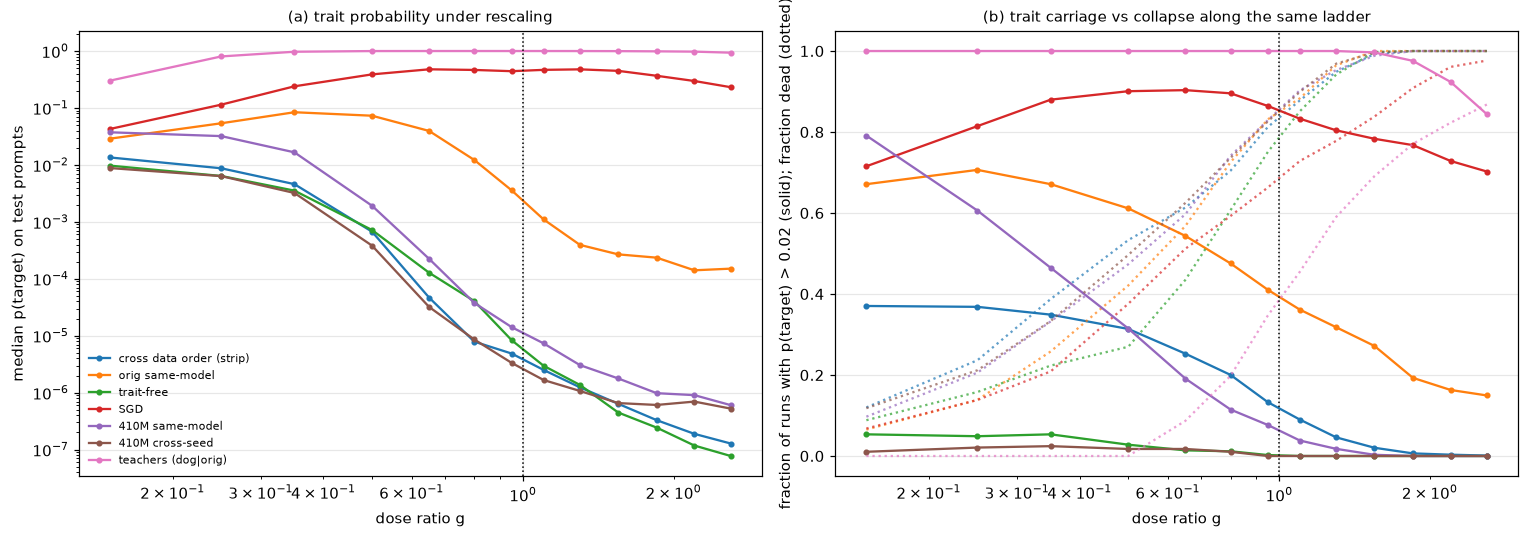

Table 5 — trait readouts at selected dose ratios (row = arm, medians over runs):
            arm  p_median_g0p5  p_median_g1p1  p_median_g2p6  carry_g0p5  carry_g1p1  dead_g1p1
          strip         0.0007         0.0000         0.0000      0.3137      0.0899     0.8779
orig_same_model         0.0731         0.0011         0.0002      0.6114      0.3614     0.8832
     trait_free         0.0007         0.0000         0.0000      0.0279      0.0000     0.8512
            sgd         0.3889         0.4669         0.2316      0.9008      0.8329     0.7285
m410_same_model         0.0019         0.0000         0.0000      0.3147      0.0382     0.9029
m410_cross_seed         0.0004         0.0000         0.0000      0.0174      0.0000     0.8993
       teachers         0.9985         0.9997         0.9349      1.0000      1.0000     0.4549


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for arm in ARMS:
    g_ = D[D.arm.eq(arm)]
    c = g_.groupby('g').agg(p=('p_target', 'median'), carry=('p_target', lambda s: (s > 0.02).mean()), dead=('dead', 'mean'))
    axes[0].plot(c.index, c.p, marker='o', ms=3, color=COL[arm], label=LABEL[arm])
    axes[1].plot(c.index, c.carry, marker='o', ms=3, color=COL[arm], label=LABEL[arm])
    axes[1].plot(c.index, c.dead, ls=':', color=COL[arm], alpha=0.7)
for ax in axes:
    ax.axvline(1, color='k', ls=':', lw=1); ax.set_xscale('log'); ax.set_xlabel('dose ratio g')
axes[0].set_yscale('log'); axes[0].set_ylabel('median p(target) on test prompts'); axes[0].set_title('(a) trait probability under rescaling', fontsize=10)
axes[1].set_ylabel('fraction of runs with p(target) > 0.02 (solid); fraction dead (dotted)'); axes[1].set_title('(b) trait carriage vs collapse along the same ladder', fontsize=10)
axes[0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(FIG / 'fig3_trait_under_rescaling.png', dpi=160, bbox_inches='tight'); plt.show()
t5 = []
for arm in ARMS:
    g_ = D[D.arm.eq(arm)]; c = g_.groupby('g').agg(p=('p_target', 'median'), carry=('p_target', lambda s: (s > 0.02).mean()), dead=('dead', 'mean'))
    t5.append(dict(arm=arm, p_median_g0p5=c.p.get(0.5), p_median_g1p1=c.p.get(1.1), p_median_g2p6=c.p.get(2.6), carry_g0p5=c.carry.get(0.5), carry_g1p1=c.carry.get(1.1), dead_g1p1=c.dead.get(1.1)))
t5 = pd.DataFrame(t5); print('Table 5 — trait readouts at selected dose ratios (row = arm, medians over runs):'); print(t5.round(4).to_string(index=False)); t5.to_csv(FIG / 'table5_trait.csv', index=False)

## §6 Provenance

- Manifests/results: `analysis/dose_rescaling_census_20260902/manifest*.json` with the matching `results*.csv` (one pair per planning pass; the notebook loads every pair as one population and asserts each results row carries its manifest's sha and that no run appears in two manifests).
- Design: `weightspace/dose_rescaling.py` (λ = g·θ/dw_fro, 13 ratios), `weightspace/dose_census.py` (arm specs, anchored θ fit, audit), `scripts/dose_rescaling_census.py` (plan / evaluate / aggregate); later planning passes at the fixed θ: `run_logs/winfill_20260902/census_winfill.py` (`plan --tag T` → `manifest_T.json`, `results_T.csv`).
- Queues: `dose-census-*` (root `run_logs/queue_angela`).
- Outputs of this notebook: `analysis/dose_rescaling_census_20260902/figures/` (fig1–3 PNG, table1–5 CSV, `per_run_crossings.csv`).